# 104 Laser × frequency importance

Which lasers and which frequencies does `s7-gpc-tukey-logpower-1k` (src7 conv encoder, gastro + plastic + cardboard,
`--signal log_power --window tukey`) actually use to draw the **vase**? 3 eval samples per box (held-out positions), one heatmap per laser grid and
per frequency band, plus the joint laser × band map.

**Checkpoint: ep500.** The run crashed at ~ep750 while saving a checkpoint (`basic_ios::clear: iostream error` in `torch.save`), so ep500
is the only one on disk; its eval IoU is close to the last logged ones.

Three ways to measure importance here, each answering a slightly different question:

| method | what it changes | what it measures | cost |
|---|---|---|---|
| **occlusion** (§3-5) | replace a laser / a 20 Hz band / a (laser, band) cell with the box's **train mean** | Δ IoU vs the true mask (task damage) and 1 − IoU(pred, clean pred) (how much the output moves) | 1 forward per cell |
| **linearized occlusion** (§6) | gradient of the BCE · (mean − x) | first-order estimate of the same Δ loss, at full 1170-bin resolution | 1 backward per sample |
| **deletion / insertion** (§7) | remove (or keep only) the top-k lasers / bands by the occlusion ranking, vs a random order | whether the ranking is *faithful*: removing the top ones should hurt much faster than random | ~1 forward per k |

Baseline = train mean, not zero: the input is `log(|X|² + 1e-6) / std`, so 0 is not "no signal" (it is a particular power level).
The mean per (laser, bin, channel) over 64 train samples of the same box is "this laser at this bin says nothing unusual".

Single-laser occlusion understates importance when neighbouring lasers are redundant (nb64 on `old-config`: per-laser leave-one-out
was ~1e-4 MSE while ~40 lasers were needed): §7's insertion curve is the check for that.

**Findings (9 samples, ep500)**
- **No small set of lasers or bands does the work.** One laser occluded: mean IoU drop 0.003, max 0.13. One 20 Hz band in every laser: mean 0.012,
  max 0.20. The important lasers differ from sample to sample, and the 3-sample box means are nearly flat. Nothing like `old-config`'s
  133-215 / 380-463 Hz dominance (nb64).
- **Frequency use is broadband, with some box flavour:** gastro leans on 540-720 Hz, plastic and cardboard on 160-180 Hz plus scattered high bands
  (cardboard 400-420 and 980-1000 Hz). Every box has bands where occluding them *raises* IoU (blue), up to +0.2 for a single cardboard sample.
- **The joint laser × band map does not factor** (rank-1 share 0.09-0.11). Single cells are ±0.01, close to the noise level, so read it as
  "spread everywhere", not as a map of where.
- **The rankings are still faithful *per sample*:** deleting the top-ranked lasers or bands kills IoU about 3× faster than a random order
  (laser deletion AUC 0.10-0.14 vs 0.28-0.37). So each sample does rely on particular lasers and bands, just not the same ones.
- **Gradient · (mean − x) agrees only moderately with occlusion** (ρ 0.47-0.72 for lasers, 0.46-0.81 for bands): it is a cheap preview, not a substitute.
- **"Hurts the mask" ≠ "moves the output":** single-laser IoU drop and output drift are close to uncorrelated (ρ −0.3 to 0.44).


In [1]:
import os, sys, random
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import yaml
from scipy.stats import spearmanr

RUN = os.environ.get("RUN", "s7-gpc-tukey-logpower-1k")
OBJECT = os.environ.get("OBJECT", "vase")
EPOCH = int(os.environ.get("EPOCH", 500))  # the run crashed saving at ~ep750: ep500 is its only checkpoint
N_PER_BOX = 3     # eval samples per box
N_REF = 64        # train samples per box averaged into the occlusion baseline
BAND_HZ = 20      # occlusion band width
SEED = 0
CHUNK = 256       # forward batch

REPO = Path.cwd().parent
sys.path.insert(0, str(REPO / "src7"))
from dataset import EXPERIMENTS, DATASETS, collect_samples, build_splits, process_x, process_y, get_data_info
from arch import Boombox

cfg = {k: v["value"] for k, v in yaml.safe_load(sorted(REPO.glob(f"wandb/run-*-{RUN}/files/config.yaml"))[-1].read_text()).items() if isinstance(v, dict) and "value" in v}
splits = DATASETS[cfg["dataset"]](cfg["test_size"], None if "all" in cfg["speakers"] else cfg["speakers"])  # the run's own split
samples = {d: m for e in sorted({s["experiment"] for s in splits.values()}) for d, m in collect_samples(EXPERIMENTS / e).items()}
dirs, metas = list(samples), list(samples.values())
idxs = build_splits(splits, metas)
info = get_data_info(samples, idxs["train"])
assert info["objects"] == cfg["objects"], "class list differs from the run's"
print(RUN, cfg["dataset"], cfg["signal"], cfg["window"], "speakers", cfg["speakers"])

BOXES = [b for b in ("gastro", "plastic", "cardboard") if f"eval/{b}/{OBJECT}" in idxs]
COLOR = dict(zip(BOXES, ["#2a78d6", "#eb6834", "#1baf7a"]))  # dataviz categorical slots 1-3
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#d43d2f"])  # blue = removing it helps, red = removing it hurts

/home/ethantu/workspace/good-vibrations/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:1061: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()


collecting 2026_09_27_gastronorm_four_objs:   0%|          | 0/6155 [00:00<?, ?it/s]

collecting 2026_09_27_gastronorm_four_objs:  11%|█         | 671/6155 [00:00<00:02, 2088.57it/s]

collecting 2026_09_27_gastronorm_four_objs:  25%|██▍       | 1525/6155 [00:00<00:01, 4074.13it/s]

collecting 2026_09_27_gastronorm_four_objs:  34%|███▍      | 2114/6155 [00:00<00:01, 2659.47it/s]

...

collecting 2026_10_11_cardboard_four_objs:  73%|███████▎  | 5247/7228 [00:01<00:00, 4110.75it/s]

collecting 2026_10_11_cardboard_four_objs:  85%|████████▍ | 6114/7228 [00:01<00:00, 4958.01it/s]

collecting 2026_10_11_cardboard_four_objs:  97%|█████████▋| 6987/7228 [00:01<00:00, 5748.73it/s]

collecting 2026_10_11_cardboard_four_objs: 100%|██████████| 7228/7228 [00:01<00:00, 4802.91it/s]

2026_10_11_cardboard_four_objs: 7228 samples, skipped 0 incomplete: []
s7-gpc-tukey-logpower-1k gastronorm_plastic_cardboard log_power tukey speakers [1, 3, 5, 7]


## 1 Samples, baseline, model

3 held-out positions per box from `eval/<box>/vase`, one random speaker each. The model is re-run on them and checked against the run's
own saved ep500 eval masks.

In [2]:
rng = random.Random(SEED)
PICK = []
for b in BOXES:
    ids = idxs[f"eval/{b}/{OBJECT}"]
    for pos in rng.sample(sorted({metas[i]["position_id"] for i in ids}), N_PER_BOX):
        PICK.append(rng.choice([i for i in ids if metas[i]["position_id"] == pos]))
BOX = [b for b in BOXES for _ in range(N_PER_BOX)]
EXP = {b: metas[idxs[f"eval/{b}/{OBJECT}"][0]]["experiment"] for b in BOXES}
REF_IDS = {b: rng.sample([i for i in idxs["train"] if metas[i]["experiment"] == EXP[b]], N_REF) for b in BOXES}

px = lambda ids: list(process_x({dirs[i]: metas[i] for i in ids}, cfg["signal"], cfg["norm"], None, cfg["window"], cfg.get("gate_ms", 0), bool(cfg.get("laser_norm", 0))))
X = torch.from_numpy(np.stack(px(PICK))).cuda()                                                     # (S,L,F,C)
REF = {b: torch.from_numpy(np.mean(px(REF_IDS[b]), 0)).cuda() for b in BOXES}                      # (L,F,C) per box
Y = torch.from_numpy(np.stack([y["y"] for y in process_y({dirs[i]: metas[i] for i in PICK}, info["objects"], info["boxes"], max(info["n_objects"]), cfg["out_h"], cfg["out_w"], False)])).cuda()  # (S,H,W)

S, L, NF, C = X.shape
FREQS = np.linspace(*info["freq_range"], NF)                                                        # (F,) Hz
BAND = np.minimum(((FREQS - FREQS[0]) // BAND_HZ).astype(int), int((FREQS[-1] - FREQS[0]) // BAND_HZ) - 1)  # (F,) band of each bin
NB = BAND.max() + 1
BAND_LO = FREQS[0] + BAND_HZ * np.arange(NB)
ROWS, COLS = info["n_laser_rows"], info["n_laser_cols"]

model = Boombox(cfg["d_model"], info, cfg["out_h"], cfg["out_w"]).cuda().eval()
model.load_state_dict(torch.load(next((REPO / f"runs/{RUN}/checkpoints").glob(f"ep{EPOCH}-*.pt")), weights_only=False)["state"]["model"])
for p in model.parameters(): p.requires_grad_(False)

def soft_iou(p, y): return torch.minimum(p, y).flatten(1).sum(1) / torch.maximum(p, y).flatten(1).sum(1).clamp_min(1e-6)  # arch.iou
@torch.no_grad()
def predict(x):  # (N,L,F,C) -> (N,H,W) in [0,1]
    with torch.autocast("cuda", torch.bfloat16):
        return torch.cat([model(dict(fft=x[k:k + CHUNK]))["mask_pred"].float() for k in range(0, len(x), CHUNK)])

P0 = predict(X)                                                                                      # (S,H,W) clean predictions
IOU0 = soft_iou(P0, Y)

saved = {}
for f in (REPO / f"runs/{RUN}/outputs_history/eval").rglob(f"ep{EPOCH:04d}-*.pt"):
    d = torch.load(f, weights_only=False)
    for p, e, pos, spk in zip(d["mask_pred"], d["info"]["experiment"], d["info"]["position_id"].tolist(), d["info"]["speaker"].tolist()): saved[e, pos, spk] = p.float()
diff = max((P0[s].cpu() - saved[metas[i]["experiment"], metas[i]["position_id"], metas[i]["speaker"]]).abs().max().item() for s, i in enumerate(PICK))
print(f"X {tuple(X.shape)}, {NB} bands of {BAND_HZ} Hz; max |mask - saved ep{EPOCH} mask| = {diff:.3f} (both bf16)")

NAME = [f"{b} p{metas[i]['position_id']} s{metas[i]['speaker']}" for b, i in zip(BOX, PICK)]
pd.DataFrame(dict(box=BOX, position=[metas[i]["position_id"] for i in PICK], speaker=[metas[i]["speaker"] for i in PICK],
                  sample=[metas[i]["sample_id"] for i in PICK], iou=IOU0.cpu().numpy().round(3)))

processing x:   0%|          | 0/9 [00:00<?, ?it/s]

processing x: 100%|██████████| 9/9 [00:00<00:00, 80.94it/s]

processing x: 100%|██████████| 9/9 [00:00<00:00, 80.62it/s]

processing x:   0%|          | 0/64 [00:00<?, ?it/s]

processing x:  14%|█▍        | 9/64 [00:00<00:00, 87.06it/s]

...

processing x: 100%|██████████| 64/64 [00:00<00:00, 85.40it/s]

processing y:   0%|          | 0/9 [00:00<?, ?it/s]

processing y: 100%|██████████| 9/9 [00:00<00:00, 300.51it/s]

X (9, 100, 1170, 2), 45 bands of 20 Hz; max |mask - saved ep500 mask| = 0.082 (both bf16)


,box,position,speaker,sample,iou
0,gastro,455,1,002269,0.596
1,gastro,568,3,002836,0.508
2,gastro,488,7,002438,0.803
3,plastic,2348,5,002348-5,0.818
4,plastic,2300,7,002300-7,0.652
5,plastic,2429,5,002429-5,0.652
6,cardboard,3440,3,003440-3,0.633
7,cardboard,3316,5,003316-5,0.739
8,cardboard,3424,3,003424-3,0.604


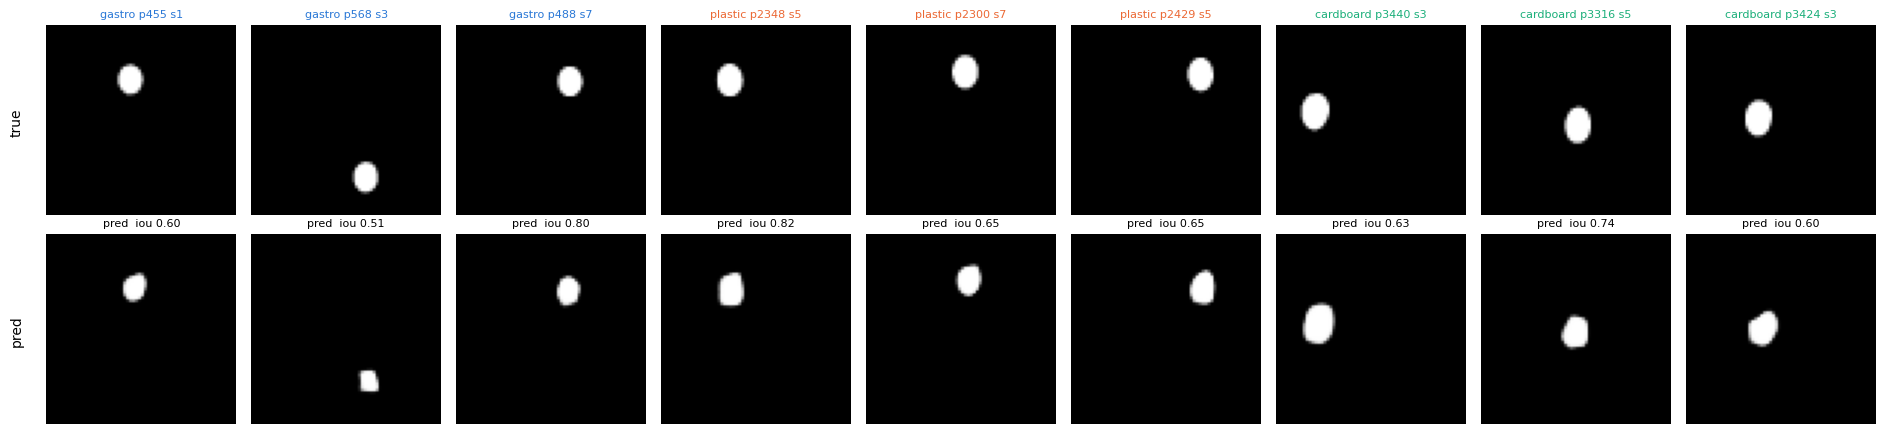

In [3]:
fig, axs = plt.subplots(2, S, figsize=(2.1 * S, 4.4))
for s in range(S):
    axs[0, s].imshow(Y[s].cpu(), cmap="gray", vmin=0, vmax=1); axs[0, s].set_title(NAME[s], fontsize=8, color=COLOR[BOX[s]])
    axs[1, s].imshow(P0[s].cpu(), cmap="gray", vmin=0, vmax=1); axs[1, s].set_title(f"pred  iou {IOU0[s]:.2f}", fontsize=8)
for ax in axs.flat: ax.axis("off")
axs[0, 0].text(-8, 32, "true", rotation=90, va="center", ha="right"); axs[1, 0].text(-8, 32, "pred", rotation=90, va="center", ha="right")
plt.tight_layout(); plt.show()

## 2 Occlusion engine

`occlude(s, lm, bm)`: for each row k, replace `X[s]` with the box's train mean where `lm[k] (L,) ⊗ bm[k] (F,)` is true, and return
- **drop** = IoU(clean pred, true) − IoU(occluded pred, true): positive = the region helped the vase mask
- **drift** = 1 − IoU(occluded pred, clean pred): how much the output changed at all, right or wrong

In [4]:
def occlude(s, lm, bm):  # lm (K,L) bool, bm (K,F) bool -> drop (K,), drift (K,)
    x, ref = X[s], REF[BOX[s]]
    drop, drift = [], []
    for k in range(0, len(lm), CHUNK):
        m = (lm[k:k + CHUNK, :, None] & bm[k:k + CHUNK, None, :])[..., None]                          # (n,L,F,1)
        p = predict(torch.where(m, ref, x))                                                          # (n,H,W)
        drop.append(IOU0[s] - soft_iou(p, Y[s].expand_as(p))); drift.append(1 - soft_iou(p, P0[s].expand_as(p)))
    return torch.cat(drop).cpu().numpy(), torch.cat(drift).cpu().numpy()

EYE_L = torch.eye(L, dtype=torch.bool, device="cuda")
BANDS = torch.from_numpy(BAND[None] == np.arange(NB)[:, None]).cuda()                               # (NB,F)
ALL_L, ALL_F = torch.ones(1, L, dtype=torch.bool, device="cuda"), torch.ones(1, NF, dtype=torch.bool, device="cuda")

LAS, LAS_DRIFT, BND, BND_DRIFT, JOINT, JOINT_DRIFT = [], [], [], [], [], []
for s in range(S):
    a, b = occlude(s, EYE_L, ALL_F.expand(L, -1)); LAS.append(a); LAS_DRIFT.append(b)                  # one laser, every freq
    a, b = occlude(s, ALL_L.expand(NB, -1), BANDS); BND.append(a); BND_DRIFT.append(b)               # one band, every laser
    a, b = occlude(s, EYE_L.repeat_interleave(NB, 0), BANDS.repeat(L, 1))                            # one (laser, band) cell
    JOINT.append(a.reshape(L, NB)); JOINT_DRIFT.append(b.reshape(L, NB))
LAS, LAS_DRIFT, BND, BND_DRIFT, JOINT, JOINT_DRIFT = map(np.stack, (LAS, LAS_DRIFT, BND, BND_DRIFT, JOINT, JOINT_DRIFT))  # (S,L) (S,NB) (S,L,NB)
print(f"laser drop  max {LAS.max():.3f}  mean {LAS.mean():.4f};  band drop max {BND.max():.3f}  mean {BND.mean():.4f};  cell drop max {JOINT.max():.3f}")

laser drop  max 0.132  mean 0.0034;  band drop max 0.202  mean 0.0117;  cell drop max 0.063


## 3 Laser heatmaps

Each laser replaced by its train mean over **all** frequencies, drawn at its place on the 10×10 grid (laser index `l` → row `l // 10`,
col `l % 10`, the layout `LaserGridEncoder` reshapes to). Red = IoU drops without it. Last column = the box's mean over its 3 samples.
The colour scale is shared by every panel.

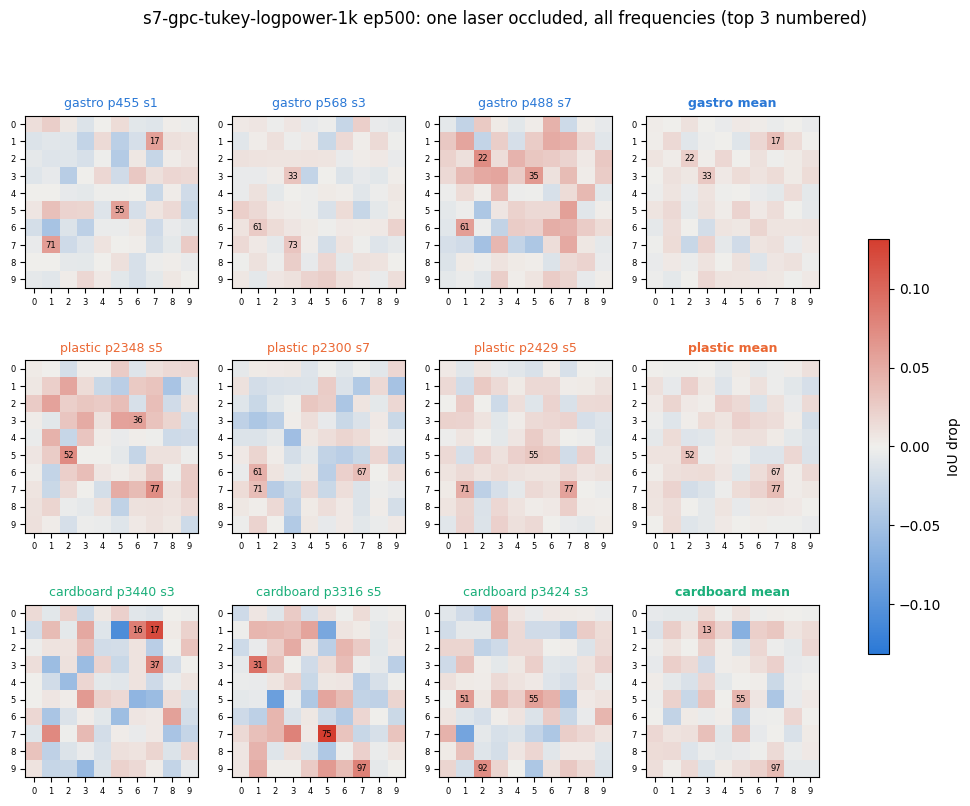

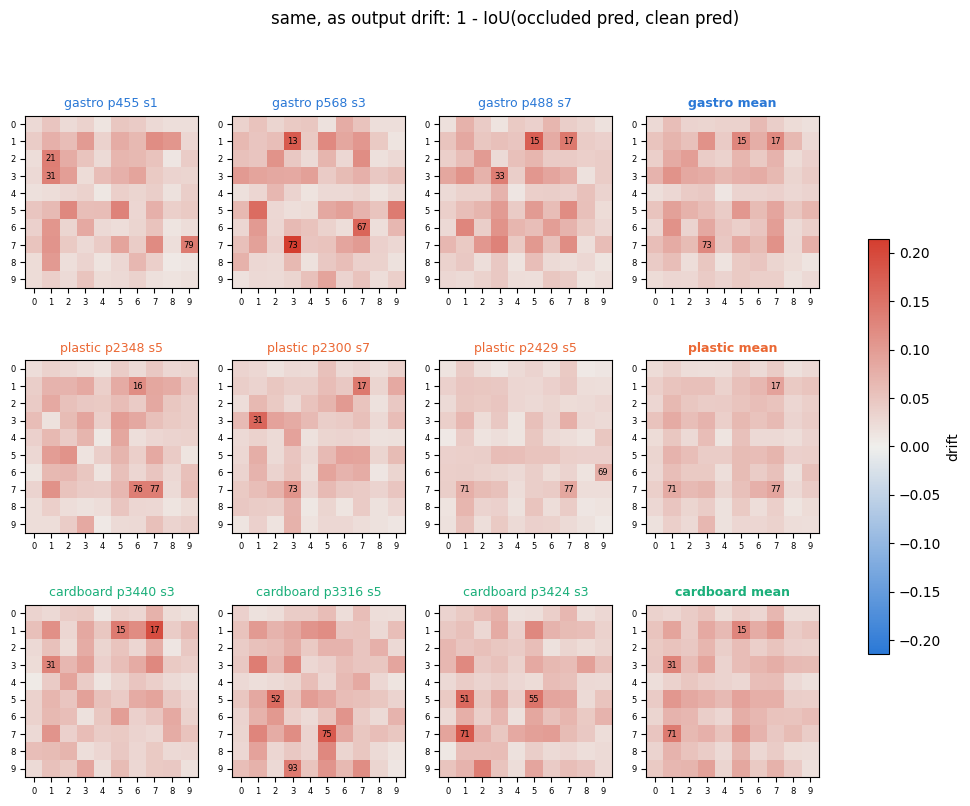

In [5]:
def grid_figure(A, title, label):  # A (S,L)
    v = np.abs(A).max()
    fig, axs = plt.subplots(len(BOXES), N_PER_BOX + 1, figsize=(3.2 * (N_PER_BOX + 1), 3.0 * len(BOXES)), squeeze=False)
    for r, b in enumerate(BOXES):
        ss = [s for s in range(S) if BOX[s] == b]
        for c, (a, t) in enumerate([*[(A[s], NAME[s]) for s in ss], (A[ss].mean(0), f"{b} mean")]):
            im = axs[r, c].imshow(a.reshape(ROWS, COLS), cmap=DIV, norm=TwoSlopeNorm(0, -v, v))
            axs[r, c].set_title(t, fontsize=9, color=COLOR[b], fontweight="bold" if c == N_PER_BOX else None)
            axs[r, c].set_xticks(range(COLS)); axs[r, c].set_yticks(range(ROWS)); axs[r, c].tick_params(labelsize=6)
            top = np.argsort(a)[-3:]
            for l in top: axs[r, c].text(l % COLS, l // COLS, l, ha="center", va="center", fontsize=6)
    fig.colorbar(im, ax=axs, shrink=0.6, label=label); fig.suptitle(title); plt.show()

grid_figure(LAS, f"{RUN} ep{EPOCH}: one laser occluded, all frequencies (top 3 numbered)", "IoU drop")
grid_figure(LAS_DRIFT, "same, as output drift: 1 - IoU(occluded pred, clean pred)", "drift")

## 4 Frequency heatmaps

Each 20 Hz band replaced by its train mean in **every** laser at once. Top: one row per sample; bottom: per-box mean.

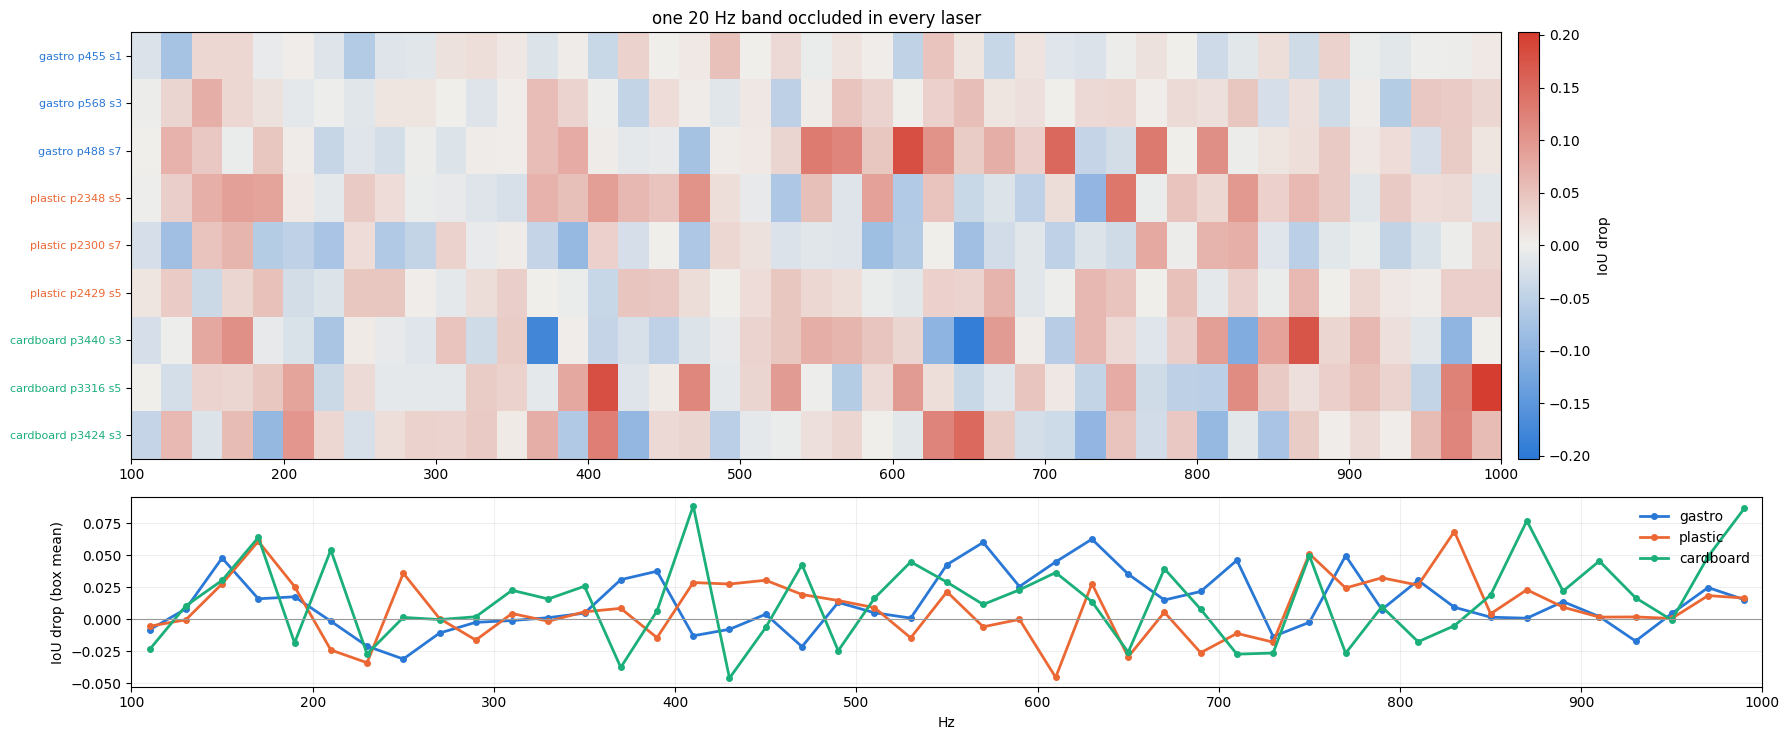

,gastro,plastic,cardboard
rank,,,
0,620-640 Hz (0.063),820-840 Hz (0.068),400-420 Hz (0.088)
1,560-580 Hz (0.060),160-180 Hz (0.061),980-1000 Hz (0.087)
2,760-780 Hz (0.050),740-760 Hz (0.051),860-880 Hz (0.077)
3,140-160 Hz (0.048),240-260 Hz (0.036),160-180 Hz (0.064)
4,700-720 Hz (0.046),780-800 Hz (0.032),200-220 Hz (0.054)
5,600-620 Hz (0.045),440-460 Hz (0.030),740-760 Hz (0.050)


In [6]:
fig, axs = plt.subplots(2, 1, figsize=(18, 7.5), gridspec_kw=dict(height_ratios=[S, 4]))
v = np.abs(BND).max()
im = axs[0].imshow(BND, cmap=DIV, norm=TwoSlopeNorm(0, -v, v), aspect="auto", extent=[FREQS[0], BAND_LO[-1] + BAND_HZ, S - 0.5, -0.5])
axs[0].set_yticks(range(S), NAME, fontsize=8)
for t, s in zip(axs[0].get_yticklabels(), range(S)): t.set_color(COLOR[BOX[s]])
fig.colorbar(im, ax=axs[0], pad=0.01, label="IoU drop")
axs[0].set_title(f"one {BAND_HZ} Hz band occluded in every laser")
for b in BOXES:
    m = BND[[s for s in range(S) if BOX[s] == b]].mean(0)
    axs[1].plot(BAND_LO + BAND_HZ / 2, m, lw=2, color=COLOR[b], label=b, marker="o", ms=4)
axs[1].axhline(0, color="#999", lw=0.8); axs[1].set_xlim(axs[0].get_xlim()); axs[1].legend(frameon=False)
axs[1].set_xlabel("Hz"); axs[1].set_ylabel("IoU drop (box mean)"); axs[1].grid(alpha=0.2)
plt.tight_layout(); plt.show()

top = pd.DataFrame({b: [f"{BAND_LO[k]:.0f}-{BAND_LO[k] + BAND_HZ:.0f} Hz ({BND[[s for s in range(S) if BOX[s] == b]].mean(0)[k]:.3f})"
                        for k in np.argsort(BND[[s for s in range(S) if BOX[s] == b]].mean(0))[::-1][:6]] for b in BOXES})
top.index.name = "rank"; top

## 5 Joint laser × frequency

Every (laser, band) cell occluded on its own: 100 × 45 per sample. Single cells are small (the other 99 lasers still carry the band), so
these maps are about *where* the model reads each band, not the size of the effect. Per-box mean over its 3 samples; lasers sorted by
their total.

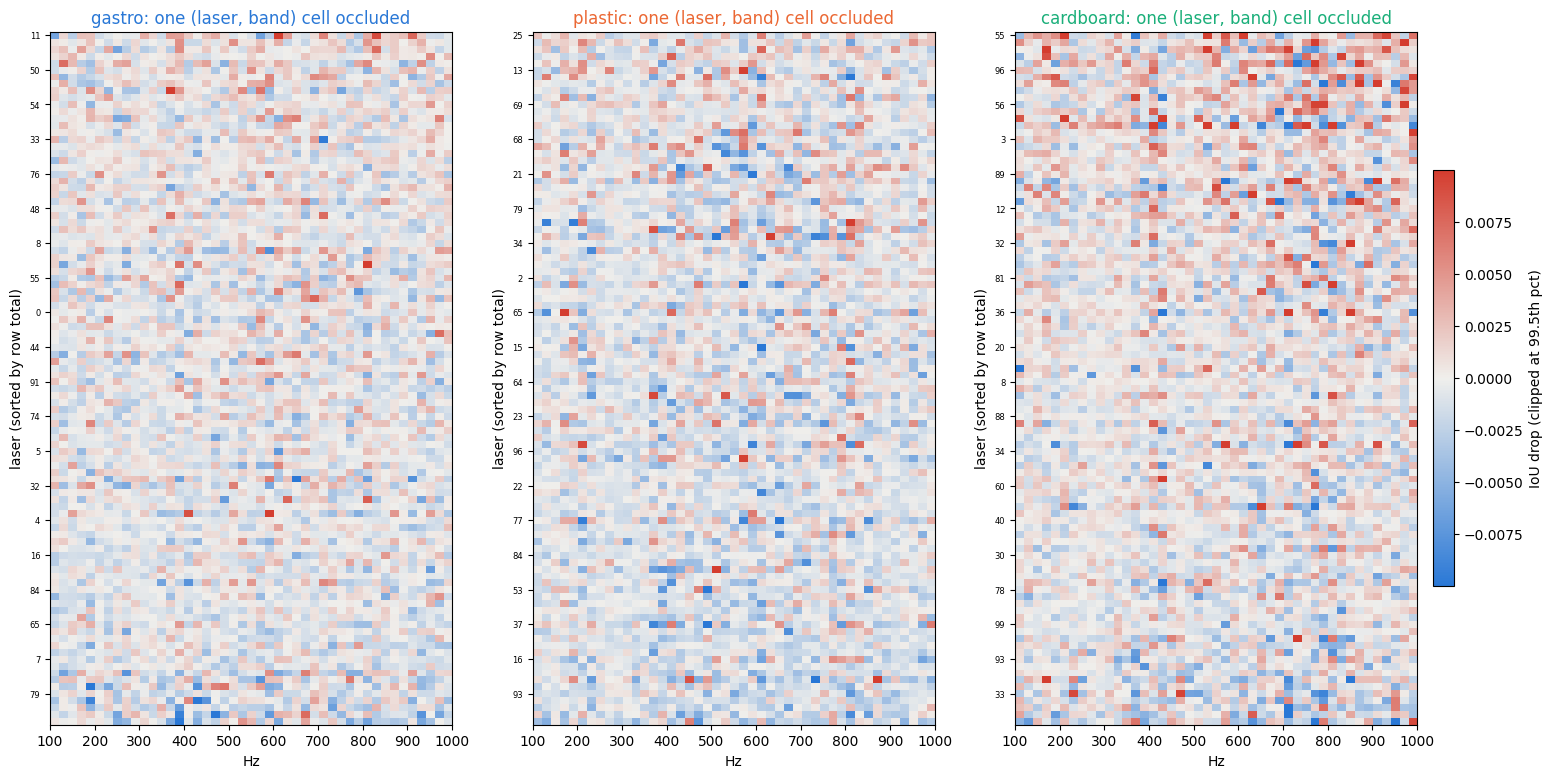

,box,rank1_share,rho_laser_vs_s3,rho_band_vs_s4
0,gastro,0.088,0.547,0.565
1,plastic,0.086,0.584,0.923
2,cardboard,0.110,0.692,0.924


In [7]:
fig, axs = plt.subplots(1, len(BOXES), figsize=(7 * len(BOXES), 9), squeeze=False)
v = np.percentile(np.abs([JOINT[[s for s in range(S) if BOX[s] == b]].mean(0) for b in BOXES]), 99.5)
for ax, b in zip(axs[0], BOXES):
    J = JOINT[[s for s in range(S) if BOX[s] == b]].mean(0)                                         # (L,NB)
    order = np.argsort(J.sum(1))[::-1]
    im = ax.imshow(J[order], cmap=DIV, norm=TwoSlopeNorm(0, -v, v), aspect="auto", extent=[FREQS[0], BAND_LO[-1] + BAND_HZ, L - 0.5, -0.5])
    ax.set_yticks(range(0, L, 5), order[::5], fontsize=6); ax.set_ylabel("laser (sorted by row total)"); ax.set_xlabel("Hz")
    ax.set_title(f"{b}: one (laser, band) cell occluded", color=COLOR[b])
fig.colorbar(im, ax=axs, shrink=0.6, pad=0.01, label="IoU drop (clipped at 99.5th pct)"); plt.show()

# does the joint map factor into laser x band? rank-1 share of its energy, and do its marginals agree with §3/§4?
rows = []
for b in BOXES:
    ss = [s for s in range(S) if BOX[s] == b]
    J = JOINT[ss].mean(0); sv = np.linalg.svd(J, compute_uv=False)
    rows.append(dict(box=b, rank1_share=sv[0] ** 2 / (sv ** 2).sum(),
                     rho_laser_vs_s3=spearmanr(J.sum(1), LAS[ss].mean(0))[0], rho_band_vs_s4=spearmanr(J.sum(0), BND[ss].mean(0))[0]))
pd.DataFrame(rows).round(3)

## 6 Linearized occlusion: gradient · (mean − x)

One backward pass of the BCE vs the true mask per sample. `g · (ref − x)` is the first-order change in loss from swapping x for the
train mean, so it estimates the same thing as §3-4 (sign: positive = removing it hurts) at the full 1170-bin, per-laser resolution
without 4500 forward passes. fp32. Bottom table: Spearman ρ between this and the occlusion maps.

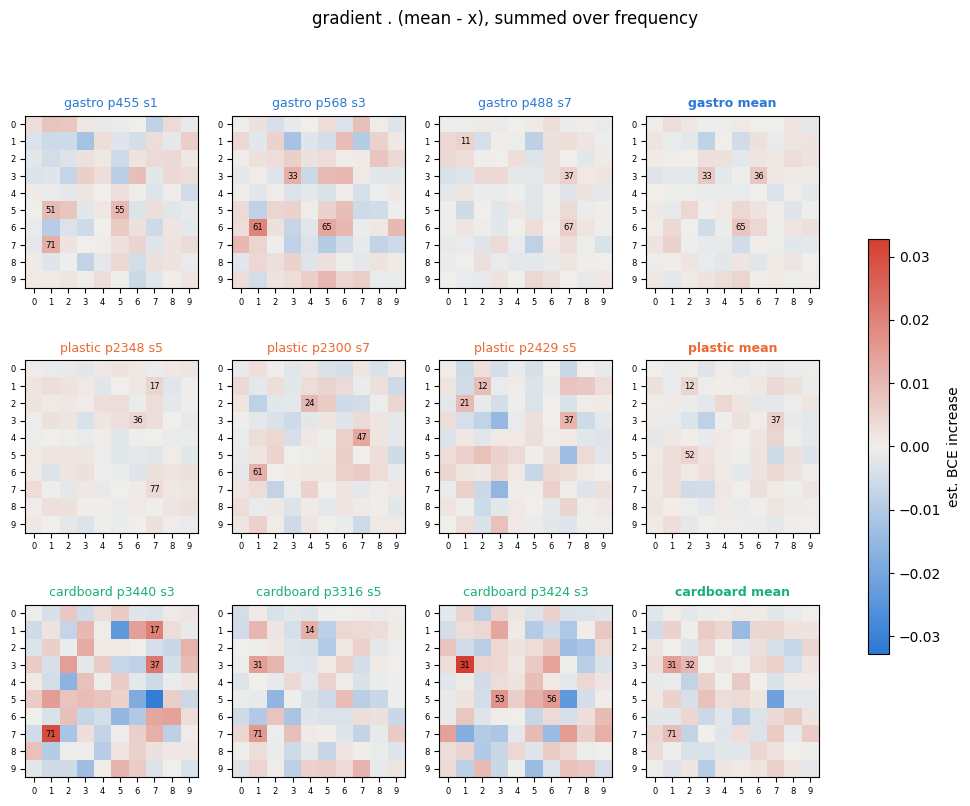

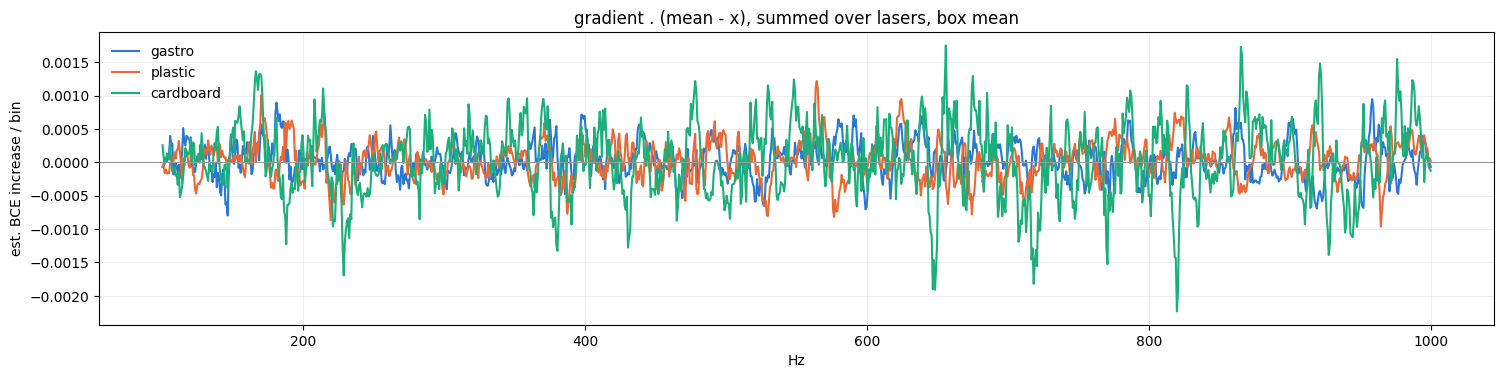

,sample,rho_laser,rho_band,rho_drop_vs_drift_laser
0,gastro p455 s1,0.67,0.61,-0.06
1,gastro p568 s3,0.47,0.46,0.14
2,gastro p488 s7,0.54,0.59,0.44
3,plastic p2348 s5,0.62,0.54,0.41
4,plastic p2300 s7,0.55,0.75,-0.31
5,plastic p2429 s5,0.62,0.65,0.35
6,cardboard p3440 s3,0.72,0.81,-0.02
7,cardboard p3316 s5,0.66,0.72,0.22
8,cardboard p3424 s3,0.57,0.73,0.00


In [8]:
LIN = []
for s in range(S):
    x = X[s:s + 1].clone().requires_grad_(True)
    loss = F.binary_cross_entropy_with_logits(model(dict(fft=x))["mask_logits"], Y[s:s + 1])
    g, = torch.autograd.grad(loss, x)
    LIN.append((g * (REF[BOX[s]] - x)).sum(-1)[0].detach().cpu().numpy())                          # (L,F), summed over x/y channel
LIN = np.stack(LIN)                                                                                  # (S,L,F)

grid_figure(LIN.sum(2), "gradient . (mean - x), summed over frequency", "est. BCE increase")

fig, ax = plt.subplots(figsize=(18, 3.8))
k = 9  # ~7 Hz smoothing
for b in BOXES:
    m = LIN[[s for s in range(S) if BOX[s] == b]].sum(1).mean(0)
    ax.plot(FREQS, np.convolve(m, np.ones(k) / k, "same"), lw=1.5, color=COLOR[b], label=b)
ax.axhline(0, color="#999", lw=0.8); ax.legend(frameon=False); ax.grid(alpha=0.2)
ax.set_xlabel("Hz"); ax.set_ylabel("est. BCE increase / bin"); ax.set_title("gradient . (mean - x), summed over lasers, box mean"); plt.show()

lin_band = np.stack([np.bincount(BAND, w, NB) for w in LIN.sum(1)])                                 # (S,NB)
pd.DataFrame(dict(sample=NAME, rho_laser=[spearmanr(LIN[s].sum(1), LAS[s])[0] for s in range(S)],
                  rho_band=[spearmanr(lin_band[s], BND[s])[0] for s in range(S)],
                  rho_drop_vs_drift_laser=[spearmanr(LAS[s], LAS_DRIFT[s])[0] for s in range(S)])).round(2)

## 7 Is the ranking faithful? Deletion and insertion

Per sample, rank lasers (and bands) by their §3/§4 occlusion drop, then
- **deletion**: occlude the top k, k = 0..all: a faithful ranking falls fast
- **insertion**: occlude everything *except* the top k: a faithful ranking recovers fast

against a random order (mean of 5). The ranking comes from the same sample it is tested on, so it is slightly optimistic; the
gap to random is what matters. Area under the curves in the table (deletion: lower = better ranking; insertion: higher).

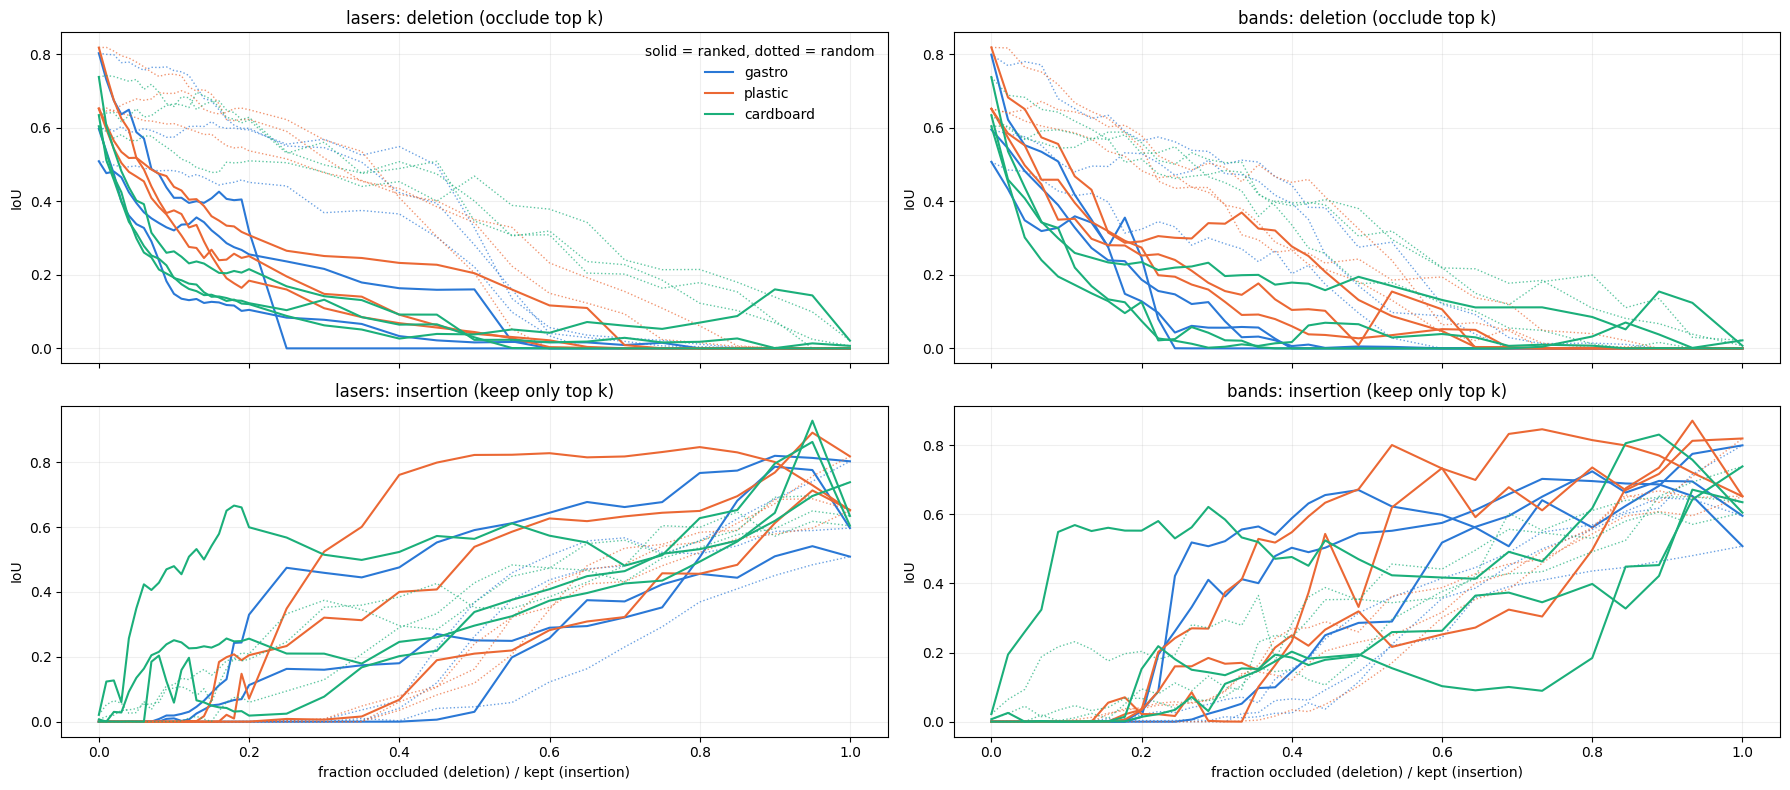

auc_ranked  auc_random
kind  mode      box                              
laser deletion  gastro          0.103       0.275
      insertion gastro          0.334       0.242
      deletion  plastic         0.139       0.311
      insertion plastic         0.422       0.265
      deletion  cardboard       0.097       0.372
      insertion cardboard       0.411       0.369
band  deletion  gastro          0.088       0.238
      insertion gastro          0.412       0.254
      deletion  plastic         0.152       0.269
      insertion plastic         0.403       0.278
      deletion  cardboard       0.106       0.307
      insertion cardboard       0.320       0.333

In [9]:
def curves(s, scores, kind):
    n = len(scores)
    ks = np.unique(np.r_[np.arange(0, min(n, 20) + 1), np.linspace(0, n, 21).astype(int)])
    def run(order):
        member = torch.zeros(len(ks), n, dtype=torch.bool, device="cuda")
        for j, k in enumerate(ks): member[j, torch.as_tensor(order[:k].copy())] = True
        out = []
        for mode in ("del", "ins"):
            m = member if mode == "del" else ~member
            lm, bm = (m, ALL_F.expand(len(ks), -1)) if kind == "laser" else (ALL_L.expand(len(ks), -1), (m.float() @ BANDS.float()).bool())
            out.append(IOU0[s].item() - occlude(s, lm, bm)[0])                                       # IoU after occluding
        return out
    best = run(np.argsort(scores)[::-1])
    rand = np.mean([run(np.random.default_rng(r).permutation(n)) for r in range(5)], 0)
    return ks / n, best, rand

fig, axs = plt.subplots(2, 2, figsize=(18, 8), sharex=True)
rows = []
for c, (kind, A) in enumerate([("laser", LAS), ("band", BND)]):
    for s in range(S):
        f, (d, i), (rd, ri) = curves(s, A[s], kind)
        for r, (y, yr, mode) in enumerate([(d, rd, "deletion"), (i, ri, "insertion")]):
            axs[r, c].plot(f, y, color=COLOR[BOX[s]], lw=1.5, label=BOX[s] if s % N_PER_BOX == 0 else None)
            axs[r, c].plot(f, yr, color=COLOR[BOX[s]], lw=1, ls=":", alpha=0.7)
            rows.append(dict(kind=kind, mode=mode, sample=NAME[s], box=BOX[s], auc_ranked=np.trapezoid(y, f), auc_random=np.trapezoid(yr, f)))
        axs[0, c].set_title(f"{kind}s: deletion (occlude top k)"); axs[1, c].set_title(f"{kind}s: insertion (keep only top k)")
for ax in axs.flat: ax.grid(alpha=0.2); ax.set_ylabel("IoU")
for ax in axs[1]: ax.set_xlabel("fraction occluded (deletion) / kept (insertion)")
axs[0, 0].legend(frameon=False, title="solid = ranked, dotted = random")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).groupby(["kind", "mode", "box"], sort=False)[["auc_ranked", "auc_random"]].mean().round(3)

## 8 Notes

Read the results above with these caveats:
- **3 samples per box** is a picture, not a statistic: re-run with `N_PER_BOX` larger (env vars `RUN`, `OBJECT`, `EPOCH`) before quoting numbers.
- Occlusion with the train mean asks "what if this laser/band looked average?"; it is not "what if the laser were missing". A different
  baseline (noise-floor, another speaker's capture, a shuffled sample) can rank differently.
- Neither occlusion nor gradients say whether the model *needs* a region, only whether this trained model *uses* it. Retraining with a
  region removed (ROAR-style: drop lasers / bands from the input at train time) is the test for "is the information elsewhere too".